<a href="https://colab.research.google.com/github/Haidriyam/victorian-serial-entropy/blob/main/serial%20entropy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[*] Downloading source text from Project Gutenberg...
[+] Loaded 15 substantive chapters.

Chapter   Total Tokens   H_Core (bits)  H_End (bits)   Delta H   
1         890            8.143          7.694          -0.449    
2         1559           8.997          7.886          -1.111    
3         1073           8.511          7.722          -0.788    
4         1511           8.653          7.689          -0.964    
5         1286           8.544          7.341          -1.203    
6         1535           9.092          7.825          -1.267    
7         1865           9.158          7.592          -1.565    
8         1043           8.755          7.737          -1.018    
9         2247           9.092          7.872          -1.220    
10        1270           8.618          7.594          -1.024    
11        1690           8.981          7.932          -1.049    
12        1780           9.114          7.760          -1.354    
13        1257           8.729          7.805      

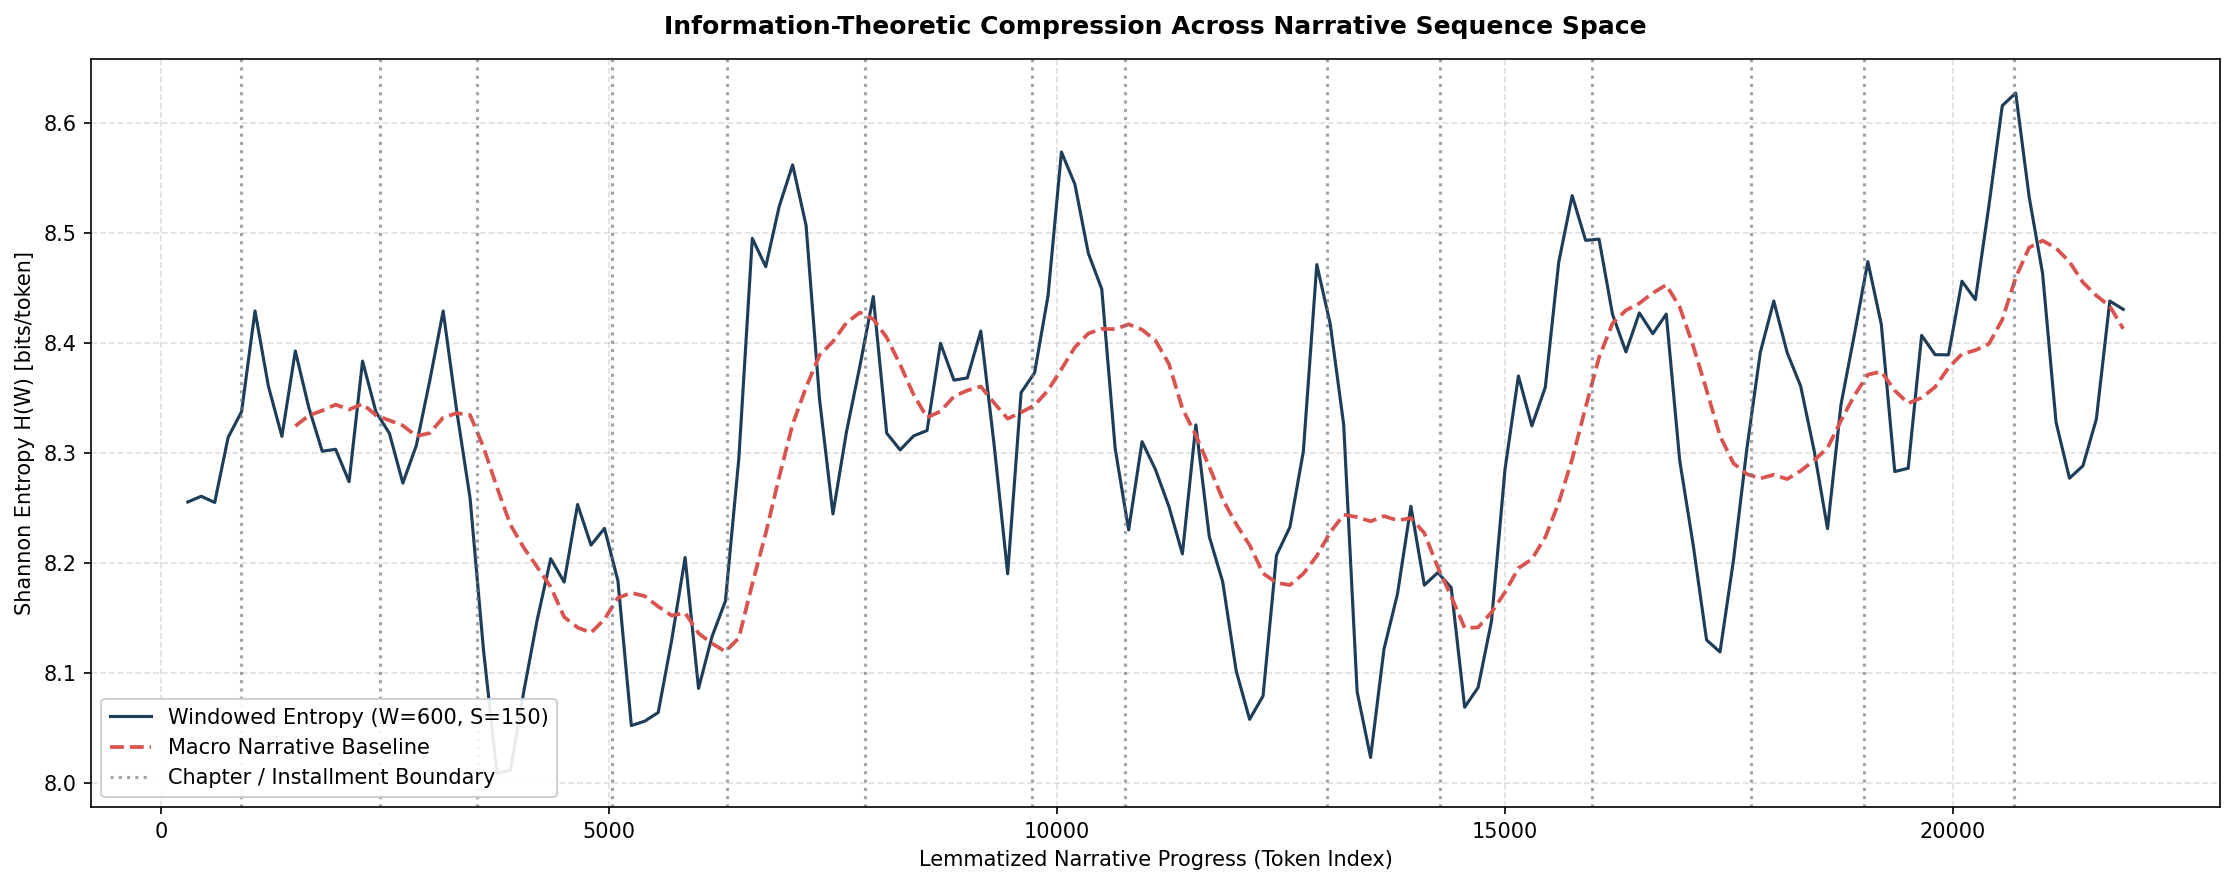

[+] Pipeline complete. Saved high-res render to entropy_plot.png


In [1]:
# ==============================================================================
# Narrative Entropy Pipeline: Testing the Informational Bottleneck Hypothesis
# Case Study: Arthur Conan Doyle - The Hound of the Baskervilles (1901)
# ==============================================================================

import sys
import subprocess

# 1. Environment bootstrap (Colab runtime setup)
try:
    import spacy
    nlp = spacy.load("en_core_web_sm", disable=["ner", "parser"])
except (ImportError, OSError):
    print("[*] Installing spacy pipeline components...")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "spacy", "matplotlib", "numpy"], check=True)
    subprocess.run([sys.executable, "-m", "spacy", "download", "en_core_web_sm"], check=True)
    import spacy
    nlp = spacy.load("en_core_web_sm", disable=["ner", "parser"])

import re
import urllib.request
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt

# 2. Pipeline parameters
CORPUS_URL = "https://www.gutenberg.org/files/2852/2852-0.txt"
CHAPTER_PATTERN = r"Chapter\s+[IVXLCDM\d]+\.?"
WINDOW_SIZE = 600
STEP_SIZE = 150
BOUNDARY_K = 350

# 3. Ingestion & Boilerplate Stripping
print("[*] Downloading source text from Project Gutenberg...")
req = urllib.request.Request(CORPUS_URL, headers={"User-Agent": "Research-Script/2.4 (Academic Verification)"})
with urllib.request.urlopen(req) as resp:
    raw_content = resp.read().decode("utf-8-sig")

header_end = re.search(r"\*\*\* START OF THE PROJECT GUTENBERG", raw_content)
footer_start = re.search(r"\*\*\* END OF THE PROJECT GUTENBERG", raw_content)
body_text = raw_content[header_end.end():footer_start.start()].strip() if (header_end and footer_start) else raw_content

raw_chunks = re.split(CHAPTER_PATTERN, body_text)
chapters = [c.strip() for c in raw_chunks if len(c.strip().split()) > 300]
print(f"[+] Loaded {len(chapters)} substantive chapters.")

# 4. Tokenization & Core Entropy Metric
def tokenize(text_block):
    doc = nlp(text_block.lower())
    return [t.lemma_ for t in doc if t.is_alpha and not t.is_stop]

def shannon_entropy(token_seq):
    if not token_seq:
        return 0.0
    N = len(token_seq)
    counts = Counter(token_seq)
    return -sum((c / N) * np.log2(c / N) for c in counts.values())

# 5. Boundary Compression Delta Analysis
print("\n" + "=" * 65)
print(f"{'Chapter':<10}{'Total Tokens':<15}{'H_Core (bits)':<15}{'H_End (bits)':<15}{'Delta H':<10}")
print("=" * 65)

chapter_tokens = []
cumulative_indices = []
running_count = 0

for idx, ch in enumerate(chapters, start=1):
    toks = tokenize(ch)
    if len(toks) < BOUNDARY_K:
        continue

    chapter_tokens.extend(toks)
    running_count += len(toks)
    cumulative_indices.append(running_count)

    core_slice = toks[:-BOUNDARY_K]
    tail_slice = toks[-BOUNDARY_K:]

    h_core = shannon_entropy(core_slice)
    h_tail = shannon_entropy(tail_slice)
    delta_h = h_tail - h_core

    chapter_tokens_count = len(toks)
    print(f"{idx:<10}{chapter_tokens_count:<15}{h_core:<15.3f}{h_tail:<15.3f}{delta_h:<10.3f}")

print("=" * 65 + "\n")

# 6. Sliding Window Trajectory
trajectory_indices = []
trajectory_h = []

for i in range(0, len(chapter_tokens) - WINDOW_SIZE + 1, STEP_SIZE):
    window = chapter_tokens[i:i + WINDOW_SIZE]
    trajectory_h.append(shannon_entropy(window))
    trajectory_indices.append(i + (WINDOW_SIZE // 2))

trajectory_indices = np.array(trajectory_indices)
trajectory_h = np.array(trajectory_h)

# 7. Visualization & Inline Rendering
fig, ax = plt.subplots(figsize=(15, 6), dpi=150)

# Raw dynamic trajectory
ax.plot(trajectory_indices, trajectory_h, color="#1e3d59", linewidth=1.5, label="Windowed Entropy (W=600, S=150)")

# Low-frequency trendline (Gaussian-like convolution)
kernel = np.ones(9) / 9
smoothed = np.convolve(trajectory_h, kernel, mode="valid")
adj_indices = trajectory_indices[len(trajectory_indices) - len(smoothed):]
ax.plot(adj_indices, smoothed, color="#d9534f", linestyle="--", linewidth=1.8, label="Macro Narrative Baseline")

# Boundary lines for chapters/installments
for b_idx, x_pos in enumerate(cumulative_indices[:-1]):
    lbl = "Chapter / Installment Boundary" if b_idx == 0 else None
    ax.axvline(x=x_pos, color="#6c757d", linestyle=":", alpha=0.65, label=lbl)

ax.set_title("Information-Theoretic Compression Across Narrative Sequence Space", fontsize=12, pad=12, weight="semibold")
ax.set_xlabel("Lemmatized Narrative Progress (Token Index)", fontsize=10)
ax.set_ylabel("Shannon Entropy H(W) [bits/token]", fontsize=10)
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend(loc="lower left", framealpha=0.9)

plt.tight_layout()
plt.savefig("entropy_plot.png", bbox_inches="tight")
plt.show()

print("[+] Pipeline complete. Saved high-res render to entropy_plot.png")